In [1]:
import numpy as np
from scipy.integrate import odeint
from scipy.interpolate import pchip_interpolate
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import spsolve
from scipy.integrate import trapz
from math import atan2, pi, sin, cos, sqrt, exp

In [ ]:
class Struct:
    pass

# System parameters (from paper Section 5)
sys = Struct()
sys.ctrl_on = 1  # control on/off switch

# Parameters from the paper
lam_val = 1.0     # lambda(x) = 1
mu_val = 2.0      # mu(x) = 2
q_val = 1.2       # q = 1.2
rho_val = 0.3     # rho = 0.3

# Event-triggered parameters (reduced R_L for more frequent triggers)
R_L = 0.1       # Lyapunov-based parameter (reduced from 0.5 for more events)
zeta = 1.5        # zeta parameter
nu_param = 1.2    # nu parameter

# Simulation parameters
sys.L = 1.0       # spatial domain [0, 1]
sys.T = 15.0      # simulation time 15 s
sys.N = 100       # number of interior spatial points
sys.N_grid = sys.N + 2
sys.N_g = 100     # number of grid points to solve kernels
sys.h = 0.01      # time step
sys.Tspan = np.arange(0, sys.T + sys.h, sys.h)
sys.Delta = sys.L / (sys.N + 1)
sys.xspan = np.linspace(0, sys.L, sys.N_grid)
# Fix: use linspace to ensure exactly N interior points
sys.xspanT = sys.xspan[1:-1]  # drop boundaries, length N

print(f"Spatial step: {sys.Delta:.4f}")
print(f"Time step: {sys.h:.4f}")
print(f"Grid points (interior N): {sys.N}")
print(f"xspanT length: {len(sys.xspanT)}")  # should be 100
print(f"Simulation horizon: {sys.T}s")

Spatial step: 0.0099
Time step: 0.0100
Grid points (interior N): 100
xspanT length: 100
Simulation horizon: 15.0s


## Define Time-Varying Coupling Coefficients

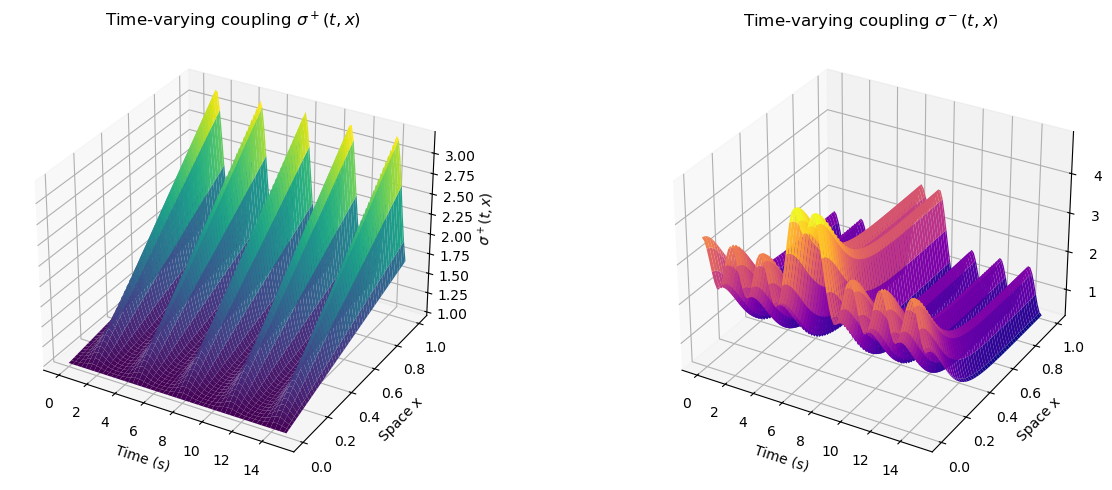

In [3]:
# System parameter functions
fun = Struct()
fun.lam = lambda x: lam_val * np.ones_like(x)  # λ(x) = 1
fun.mu = lambda x: mu_val * np.ones_like(x)    # μ(x) = 2
fun.q = q_val                                   # q = 1.2
fun.rho = rho_val                               # ρ = 0.3
fun.lam_d = lambda x: 0*np.ones_like(x)  # λ'(x) = 0
fun.mu_d = lambda x: 0*np.ones_like(x)  # μ'(x) = 0

# Time- and space-varying coupling coefficients σ+(t,x) and σ-(t,x)
# Aggressive strategy: larger amplitude, multi-frequency components for frequent triggers
T_period = 15.0  # simulation period for frequency calculation

def sigma_plus(t, x):
    """σ+(t,x) = 2 + 0.5*[sin(2πt/T) + 0.5*sin(4πt/T)]*sin(πx) — multi-frequency, larger amplitude."""
    # return 2.0 + 0.5 * (np.sin(2.0 * np.pi * t / T_period) + 
                        # 0.5 * np.sin(4.0 * np.pi * t / T_period)) * np.sin(np.pi * x)
    return 1 + 0.3 * x * np.exp(2.0*(np.sin(t))**2)

def sigma_minus(t, x):
    """σ-(t,x) = 1 + 0.45*[cos(2πt/T) + 0.5*cos(4πt/T)]*sin(πx) — multi-frequency, larger amplitude."""
    
    return 1.0 + 2.0/((np.cosh((t-7)**2))**2) + 0.6*np.cos(np.pi*t) + 2.0/((np.cosh(5*x))**2)

# Visualize coupling coefficients
t_test = np.linspace(0, 15, 100)
x_test = np.linspace(0, 1, 100)
T_mesh, X_mesh = np.meshgrid(t_test, x_test)
Sigma_plus = sigma_plus(T_mesh, X_mesh)
Sigma_minus = sigma_minus(T_mesh, X_mesh)

fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T_mesh, X_mesh, Sigma_plus, cmap='viridis')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Space x')
ax1.set_zlabel(r'$\sigma^+(t,x)$')
ax1.set_title(r'Time-varying coupling $\sigma^+(t,x)$')

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T_mesh, X_mesh, Sigma_minus, cmap='plasma')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Space x')
ax2.set_zlabel(r'$\sigma^-(t,x)$')
ax2.set_title(r'Time-varying coupling $\sigma^-(t,x)$')
plt.tight_layout()
plt.show()

## Kernel Solver (similar to the original, but using frozen parameters)

In [4]:
def solver_2x2(params, N_g):
    """Solve the backstepping kernels K and L on the triangular domain."""
    Delta = 1 / (N_g - 1)
    numTot = int(N_g*(N_g + 1) / 2)

    # Map lower-triangular indices to global indices
    index_map = np.zeros((N_g, N_g))
    index_map[np.tril_indices(N_g)] = np.arange(1, numTot+1)
    index_map = np.transpose(index_map)

    dummy1 = np.tril(np.reshape(np.arange(1, (N_g**2)+1), (N_g, N_g))).transpose()
    glob_to_mat = dummy1[dummy1 > 0]
    glob_to_mat = np.array(sorted(glob_to_mat))

    indexes = np.kron(np.arange(1, (2*numTot)+1), np.ones(5)).reshape((2*numTot,5)).astype(int)
    indexes = indexes - 1
    weights = np.zeros((2*numTot, 5))
    RHS = np.zeros((2*numTot, 1))

    # Directional derivatives (characteristics)
    s_K_x, s_K_y = np.meshgrid(params.mu, -params.lam)
    s_L_x, s_L_y = np.meshgrid(params.mu, params.mu)

    s_K = np.sqrt(s_K_x**2 + s_K_y**2)
    s_L = np.sqrt(s_L_x**2 + s_L_y**2)

    # K: iterate over triangular region
    for indX in range(N_g):
        for indY in range(indX+1):
            glob_ind = int(index_map[indY, indX])
            if (indY == indX):
                # boundary condition on the diagonal
                weights[glob_ind-1, 0] = 1
                RHS[glob_ind-1] = params.f[indY]
            else:
                theta = np.arctan2(s_K_x[indY, indX], -s_K_y[indY, indX])
                if theta > np.pi / 4:
                    sigma = Delta / np.sin(theta)
                    d = sigma * np.cos(theta)
                    preFactor = (s_K[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX - 1])-1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY, indX - 1])-1
                else:
                    sigma = Delta / np.cos(theta)
                    d = sigma * np.sin(theta)
                    preFactor = (s_K[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX - 1])-1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY + 1, indX])-1

                # handle near-diagonal correction
                if indY == indX - 1:
                    if theta > np.pi / 4:
                        weights[glob_ind-1, 2] = weights[glob_ind-1, 2] + weights[glob_ind-1, 1]
                        weights[glob_ind-1, 0] = weights[glob_ind-1, 0] - weights[glob_ind-1, 1]
                        indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX])-1
                    else:
                        weights[glob_ind-1, 2] = weights[glob_ind-1, 2] + weights[glob_ind-1, 1]
                        weights[glob_ind-1, 0] = weights[glob_ind-1, 0] - weights[glob_ind-1, 1]
                        indexes[glob_ind-1, 1] = int(index_map[indY, indX - 1])-1
    
    # L: iterate over triangular region
    for indX in range(N_g):
        for indY in range(indX + 1):
            glob_ind = int(index_map[indY, indX]) + numTot
            if indY == 0:
                # boundary condition on the bottom edge
                weights[glob_ind-1, 0] = -1
                weights[glob_ind-1, 1] = params.q
                indexes[glob_ind-1, 1] = glob_ind - numTot - 1
            else:
                theta = np.arctan2(s_L_y[indY, indX], s_L_x[indY, indX])
                if theta < np.pi / 4:
                    sigma = Delta / np.cos(theta)
                    d = sigma * np.sin(theta)
                    preFactor = (s_L[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY, indX - 1]) + numTot - 1
                    weights[glob_ind-1, 2] = -preFactor * d / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY - 1, indX - 1]) + numTot - 1
                else:
                    sigma = Delta / np.sin(theta)
                    d = sigma * np.cos(theta)
                    preFactor = (s_L[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY - 1, indX - 1]) + numTot - 1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY - 1, indX]) + numTot - 1

    # Source terms coupling K and L blocks
    for indX in range(N_g):
        for indY in range(indX+1):
            glob_ind = int(index_map[indY, indX])
            if indY != indX:
                weights[glob_ind-1, 3] = -params.a_1[indY, indX]
                weights[glob_ind-1, 4] = -params.a_2[indY, indX]
                indexes[glob_ind-1, 4] = glob_ind + numTot - 1

            if indY != 0:
                weights[glob_ind-1+numTot, 3] = -params.b_1[indY, indX]
                indexes[glob_ind-1+numTot, 3] = glob_ind - 1
                weights[glob_ind-1+numTot, 4] = -params.b_2[indY, indX]

    # Assemble sparse system and solve
    counter = 0
    A_coord_x = np.zeros(2*numTot * 5, dtype=int)
    A_coord_y = np.zeros(2*numTot * 5, dtype=int)
    A_vals = np.zeros(2*numTot * 5)
    b_coord_y = np.zeros(2*numTot, dtype=int)
    b_vals = np.zeros(2*numTot)

    for i in range(2*numTot):
        for j in range(5):
            A_coord_y[counter] = i
            A_coord_x[counter] = indexes[i, j]
            A_vals[counter] = weights[i, j]
            counter += 1
        b_coord_y[i] = i
        b_vals[i] = RHS[i][0]

    A = csr_matrix((A_vals, (A_coord_y, A_coord_x)), shape=(2*numTot, 2*numTot))
    b = csr_matrix((b_vals, (b_coord_y, np.zeros(2*numTot))), shape=(2*numTot, 1))

    x = spsolve(A, b)

    K = np.zeros((N_g, N_g))
    L = np.zeros((N_g, N_g))

    K_dummy = x[:numTot]
    L_dummy = x[numTot:2*numTot]

    K[np.tril_indices(N_g)] = K_dummy
    L[np.tril_indices(N_g)] = L_dummy
    K = K.transpose()
    L = L.transpose()

    return K, L

## Event-Triggered Kernel Solver

Recompute kernels at each event time using frozen parameters.

In [5]:
def compute_kernel_at_event(t_event, N_g, fun, q_val, rho_val):
    """
    Compute kernels at an event time with frozen σ+(t_event, x) and σ-(t_event, x).
    Returns Kvu and Kvv blocks (rolled-back version).
    """
    xspan = np.linspace(0, 1, N_g)
    params = Struct()
    params.mu = fun.mu(xspan)
    params.lam = fun.lam(xspan)
    params.lam_d = fun.lam_d(xspan)
    params.mu_d = fun.mu_d(xspan)
    params.a_1 = np.zeros((N_g, N_g))
    params.a_2 = np.zeros((N_g, N_g))
    params.b_1 = np.zeros((N_g, N_g))
    params.b_2 = np.zeros((N_g, N_g))

    # Use frozen coupling coefficients at t_event
    for i in range(N_g):
        for j in range(N_g):
            # frozen σ-(t_event, xi)
            params.a_1[i, j] = fun.lam_d(xspan[i])
            # frozen σ+(t_event, xi)
            params.a_2[i, j] = sigma_minus(t_event, xspan[i])
            # frozen σ+(t_event, xi)
            params.b_1[i, j] = sigma_plus(t_event, xspan[i])
            # frozen σ-(t_event, xi)
            params.b_2[i, j] = -fun.mu_d(xspan[i])
    
    # Boundary/source terms
    params.f = -(sigma_minus(t_event, xspan)) / (fun.lam(xspan) + fun.mu(xspan))
    params.q = q_val * fun.lam(0) / fun.mu(0)
    
    Kvu, Kvv = solver_2x2(params, N_g)
    return Kvu, Kvv

# Test kernel computation at t=0
print("Computing initial kernels (t=0)...")
K_test, L_test = compute_kernel_at_event(0, sys.N_g, fun, q_val, rho_val)
print(f"Kernel Kvu shape: {K_test.shape}")
print(f"Kernel Kvv shape: {L_test.shape}")
print(f"Kernel Kvu norm: {np.linalg.norm(K_test):.4f}")
print(f"Kernel Kvv norm: {np.linalg.norm(L_test):.4f}")

Computing initial kernels (t=0)...
Kernel Kvu shape: (100, 100)
Kernel Kvv shape: (100, 100)
Kernel Kvu norm: 63.4025
Kernel Kvv norm: 67.4403


In [6]:
def compute_kernel_at_event_firsttwo(t_event, N_g, fun, q_val, rho_val):
    """
    Compute kernels at an event time with frozen σ+(t_event, x) and σ-(t_event, x).
    Returns Kvu and Kvv blocks (rolled-back version).
    """
    xspan = np.linspace(0, 1, N_g)
    params = Struct()
    params.mu = fun.lam(xspan)
    params.lam = fun.mu(xspan)
    params.lam_d = fun.mu_d(xspan)
    params.mu_d = fun.lam_d(xspan)
    params.a_1 = np.zeros((N_g, N_g))
    params.a_2 = np.zeros((N_g, N_g))
    params.b_1 = np.zeros((N_g, N_g))
    params.b_2 = np.zeros((N_g, N_g))

    # Use frozen coupling coefficients at t_event
    for i in range(N_g):
        for j in range(N_g):
            # frozen σ-(t_event, xi)
            params.a_1[i, j] = fun.mu_d(xspan[i])
            # frozen σ+(t_event, xi)
            params.a_2[i, j] = -sigma_plus(t_event, xspan[i])
            # frozen σ+(t_event, xi)
            params.b_1[i, j] = -sigma_minus(t_event, xspan[i])
            # frozen σ-(t_event, xi)
            params.b_2[i, j] = -fun.lam_d(xspan[i])
    
    # Boundary/source terms
    params.f = (sigma_plus(t_event, xspan)) / (fun.lam(xspan) + fun.mu(xspan))
    params.q = fun.mu(0) / (fun.lam(0)*q_val)
    
    Kuv, Kuu = solver_2x2(params, N_g)
    return Kuv, Kuu

# Test kernel computation at t=0
print("Computing initial kernels (t=0)...")
Kuv_test, Kuu_test = compute_kernel_at_event_firsttwo(0, sys.N_g, fun, q_val, rho_val)
print(f"Kernel Kuv shape: {Kuv_test.shape}")
print(f"Kernel Kuu shape: {Kuu_test.shape}")
print(f"Kernel Kuv norm: {np.linalg.norm(Kuv_test):.4f}")
print(f"Kernel Kuu norm: {np.linalg.norm(Kuu_test):.4f}")

Computing initial kernels (t=0)...
Kernel Kuv shape: (100, 100)
Kernel Kuu shape: (100, 100)
Kernel Kuv norm: 26.2549
Kernel Kuu norm: 20.7060


## Lyapunov Function and Event-Triggering Condition

In [7]:
def compute_phi(xspan, coeff_vals):
    """Compute φ(x) = ∫ (1/coeff) dx using cumulative trapezoid approximation via uniform grid."""
    phi = np.zeros_like(xspan)
    dx = np.diff(xspan)
    phi[1:] = np.cumsum(dx / coeff_vals[:-1])
    return phi


def compute_lyapunov_V(u, v, xspan):
    """Lyapunov functional V(t) with exponential weights from the paper."""
    lam_vals = fun.lam(xspan)
    mu_vals = fun.mu(xspan)
    phi1 = compute_phi(xspan, lam_vals)
    phi2 = compute_phi(xspan, mu_vals)
    weight_u = np.exp(-nu_param * phi1) / lam_vals
    weight_v = zeta * np.exp(nu_param * phi2) / mu_vals
    return trapz(weight_u * (u ** 2) + weight_v * (v ** 2), xspan)


def compute_error_term(u, v, t, t_event, xspan):
    """
    Error terms (simplified version):
      e_{j,1}(t,x) = δσ+(t,x) * v(t,x)
      e_{j,2}(t,x) = δσ-(t,x) * u(t,x)
    where δσ±(t,x) := σ±(t,x) - σ±(t_j, x).
    """
    delta_sigma_plus = sigma_plus(t, xspan) - sigma_plus(t_event, xspan)
    delta_sigma_minus = sigma_minus(t, xspan) - sigma_minus(t_event, xspan)
    e1 = delta_sigma_plus * v
    e2 = delta_sigma_minus * u
    return e1, e2


def check_lyapunov_triggering_condition(u, v, t, t_event, xspan, R_L):
    """Check 2⟨g w, e_j⟩ > ν R_L V(t) with weights g from V."""
    lam_vals = fun.lam(xspan)
    mu_vals = fun.mu(xspan)
    phi1 = compute_phi(xspan, lam_vals)
    phi2 = compute_phi(xspan, mu_vals)
    weight_u = np.exp(-nu_param * phi1) / lam_vals
    weight_v = zeta * np.exp(nu_param * phi2) / mu_vals

    V_t = compute_lyapunov_V(u, v, xspan)
    e1, e2 = compute_error_term(u, v, t, t_event, xspan)

    inner = 2.0 * trapz(weight_u * u * e1 + weight_v * v * e2, xspan)
    return inner > (nu_param * R_L * V_t), inner, V_t

print(f"Event-triggering params: R_L={R_L}, zeta={zeta}, nu={nu_param}")

Event-triggering params: R_L=0.1, zeta=1.5, nu=1.2


## ODE Dynamics (with Event-Triggered Gain Scheduling)

In [8]:
def ode_dynamic_etc(x, t, sys, current_Kvu, current_Kvv,current_Kuu, current_Kuv):
    """
    ODE dynamics using the current frozen kernels at the latest event.
    """
    N = sys.N
    N_grid = sys.N_grid
    
    dummy = np.reshape(x[0:2*N], (N, 2), order='F')
    # ghost points for boundary conditions (linear extrapolation)
    dummy_a = np.vstack([2*dummy[0, :] - dummy[1, :], dummy, 2*dummy[N-1, :] - dummy[N-2, :]])

    u_sf_a = dummy_a[:, 0]
    u_sf = u_sf_a[1:N+1]
    v_sf_a = dummy_a[:, 1]
    v_sf = v_sf_a[1:N+1]

    # Boundary control input (using frozen kernels)
    if sys.ctrl_on == 1:
        # interpolate kernels to current spatial grid and integrate
        Kuu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuu[:, -1], sys.xspan)
        Kuv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuv[:, -1], sys.xspan)
        Kvu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvu[:, -1], sys.xspan)
        Kvv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvv[:, -1], sys.xspan)
        U_sf = trapz((Kvu_interp- rho_val*Kuu_interp ) * u_sf_a, sys.xspan, axis=-1) + trapz(( Kvv_interp-rho_val*Kuv_interp) * v_sf_a, sys.xspan, axis=-1)
        # U_sf = trapz(Kvu_interp*u_sf_a, sys.xspan, axis=-1) +trapz(Kvv_interp*v_sf_a, sys.xspan, axis=-1)
    else:
        U_sf = 0
    
    # Boundary conditions
    u_sf_a[0] = fun.q * v_sf_a[0]
    v_sf_a[N_grid - 1] = fun.rho * u_sf_a[N_grid - 1] + U_sf

    # Spatial derivatives (upwind-like one-sided and interior formulas)
    u_sf_x = np.hstack([(u_sf_a[1] - u_sf_a[0]) / sys.Delta,
                        (u_sf_a[0:(N_grid - 3)] - 4 * u_sf_a[1:(N_grid - 2)] + 3 * u_sf_a[2:(N_grid - 1)]) / (2 * sys.Delta)])
    v_sf_x = np.hstack([(-3 * v_sf_a[1:(N_grid - 2)] + 4 * v_sf_a[2:(N_grid - 1)] - v_sf_a[3:N_grid]) / (2 * sys.Delta),
                         (v_sf_a[N_grid - 1] - v_sf_a[N_grid - 2]) / sys.Delta])

    # PDE dynamics (use real-time time-varying coefficients)
    lam_vals = fun.lam(sys.xspanT)
    mu_vals = fun.mu(sys.xspanT)
    sigma_plus_vals = sigma_plus(t, sys.xspanT)
    sigma_minus_vals = sigma_minus(t, sys.xspanT)
    
    u_sf_t = -lam_vals * u_sf_x + sigma_plus_vals * v_sf
    v_sf_t = mu_vals * v_sf_x + sigma_minus_vals * u_sf

    dt = np.hstack([u_sf_t, v_sf_t])
    return dt

print("ODE dynamics function defined")

ODE dynamics function defined


## Main Simulation Loop — Lyapunov-based Event-Triggered Gain Scheduling

In [9]:
# Initial conditions
from calendar import c


u_sf_0 = 0.1 * np.sin(3 * np.pi * sys.xspanT / sys.L)
v_sf_0 = -0.1 * np.sin(3 * np.pi * sys.xspanT / sys.L)
x0 = np.hstack((u_sf_0, v_sf_0))

# Logs
x_log_all = np.zeros((len(sys.Tspan), len(x0)))
x_log_all[0, :] = x0
event_times = [0.0]
V_log = np.zeros(len(sys.Tspan))
error_log = np.zeros(len(sys.Tspan))
U_log = np.zeros(len(sys.Tspan))

# Initial kernel computation (returns Kvu, Kvv)
print("\nStarting simulation...")
print("Computing initial kernels (t=0)...")
current_Kvu, current_Kvv = compute_kernel_at_event(0.0, sys.N_g, fun, q_val, rho_val)
current_Kuv, current_Kuu = compute_kernel_at_event_firsttwo(0.0, sys.N_g, fun, q_val, rho_val)
print("Initial kernels computed.")
current_event_time = 0.0
num_events = 1

# Main simulation loop
for i in range(1, len(sys.Tspan)):
    t_current = sys.Tspan[i]
    t_prev = sys.Tspan[i-1]
    
    # Integrate one step (pass the current Kvu/Kvv)
    x_log, info = odeint(ode_dynamic_etc, x0, [t_prev, t_current], 
                         args=(sys, current_Kvu, current_Kvv,current_Kuu, current_Kuv), full_output=True)
    x_log_all[i, :] = x_log[-1, :]
    x0 = x_log[-1, :]
    
    # Extract u and v
    u_current = x0[:sys.N]
    v_current = x0[sys.N:2*sys.N]
    
    # Control input (consistent with ODE computation)
    dummy_a = np.hstack([2*u_current[0] - u_current[1], u_current, 2*u_current[-1] - u_current[-2]])
    dummy_v = np.hstack([2*v_current[0] - v_current[1], v_current, 2*v_current[-1] - v_current[-2]])
    Kvu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvu[:, -1], sys.xspan)
    Kvv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvv[:, -1], sys.xspan)
    Kuv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuv[:, -1], sys.xspan)
    Kuu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuu[:, -1], sys.xspan)
    # U_sf_current = trapz(Kvu_interp * dummy_a, sys.xspan) + trapz(Kvv_interp * dummy_v, sys.xspan)
    U_sf_current = trapz((rho_val*Kuu_interp - Kvu_interp) * dummy_a, sys.xspan) + trapz((rho_val*Kuv_interp-Kvv_interp) * dummy_v, sys.xspan)
    U_log[i] = U_sf_current
    
    # Lyapunov and triggering
    V_current = compute_lyapunov_V(u_current, v_current, sys.xspanT)
    V_log[i] = V_current
    should_trigger, inner_val, V_val = check_lyapunov_triggering_condition(
        u_current, v_current, t_current, current_event_time, sys.xspanT, R_L)
    error_log[i] = inner_val
    
    if should_trigger:
        print(f"Event {num_events}: t={t_current:.4f}s, V={V_val:.6f}, inner={inner_val:.6f}")
        event_times.append(t_current)
        current_event_time = t_current
        num_events += 1
        current_Kvu, current_Kvv = compute_kernel_at_event(t_current, sys.N_g, fun, q_val, rho_val)
        current_Kuv, current_Kuu = compute_kernel_at_event_firsttwo(t_current, sys.N_g, fun, q_val, rho_val)
    
    if i % 200 == 0:
        print(f"Progress: t={t_current:.2f}s / {sys.T}s, events={num_events}, V={V_current:.6f}")

print(f"\nSimulation finished! Total events: {num_events}, mean inter-event: {sys.T / num_events:.4f}s")


Starting simulation...
Computing initial kernels (t=0)...
Initial kernels computed.
Event 1: t=0.5500s, V=0.003898, inner=0.000563
Event 2: t=1.3500s, V=0.001128, inner=0.000136
Event 3: t=1.5600s, V=0.000809, inner=0.000192
Event 4: t=1.9100s, V=0.000551, inner=0.000073
Progress: t=2.00s / 15.0s, events=5, V=0.000536
Event 5: t=2.4200s, V=0.000267, inner=0.000036
Event 6: t=2.5900s, V=0.000220, inner=0.000035
Event 7: t=2.7400s, V=0.000166, inner=0.000020
Event 8: t=2.9500s, V=0.000134, inner=0.000022
Event 9: t=3.4000s, V=0.000068, inner=0.000009
Event 10: t=3.7100s, V=0.000045, inner=0.000006
Event 11: t=3.9900s, V=0.000029, inner=0.000004
Progress: t=4.00s / 15.0s, events=12, V=0.000029
Event 12: t=4.4400s, V=0.000018, inner=0.000003
Event 13: t=4.6600s, V=0.000013, inner=0.000002
Event 14: t=5.0400s, V=0.000007, inner=0.000001
Event 15: t=5.4800s, V=0.000004, inner=0.000001
Event 16: t=5.6400s, V=0.000003, inner=0.000001
Event 17: t=5.8100s, V=0.000002, inner=0.000000
Event 18: t

## Post-processing and Visualization

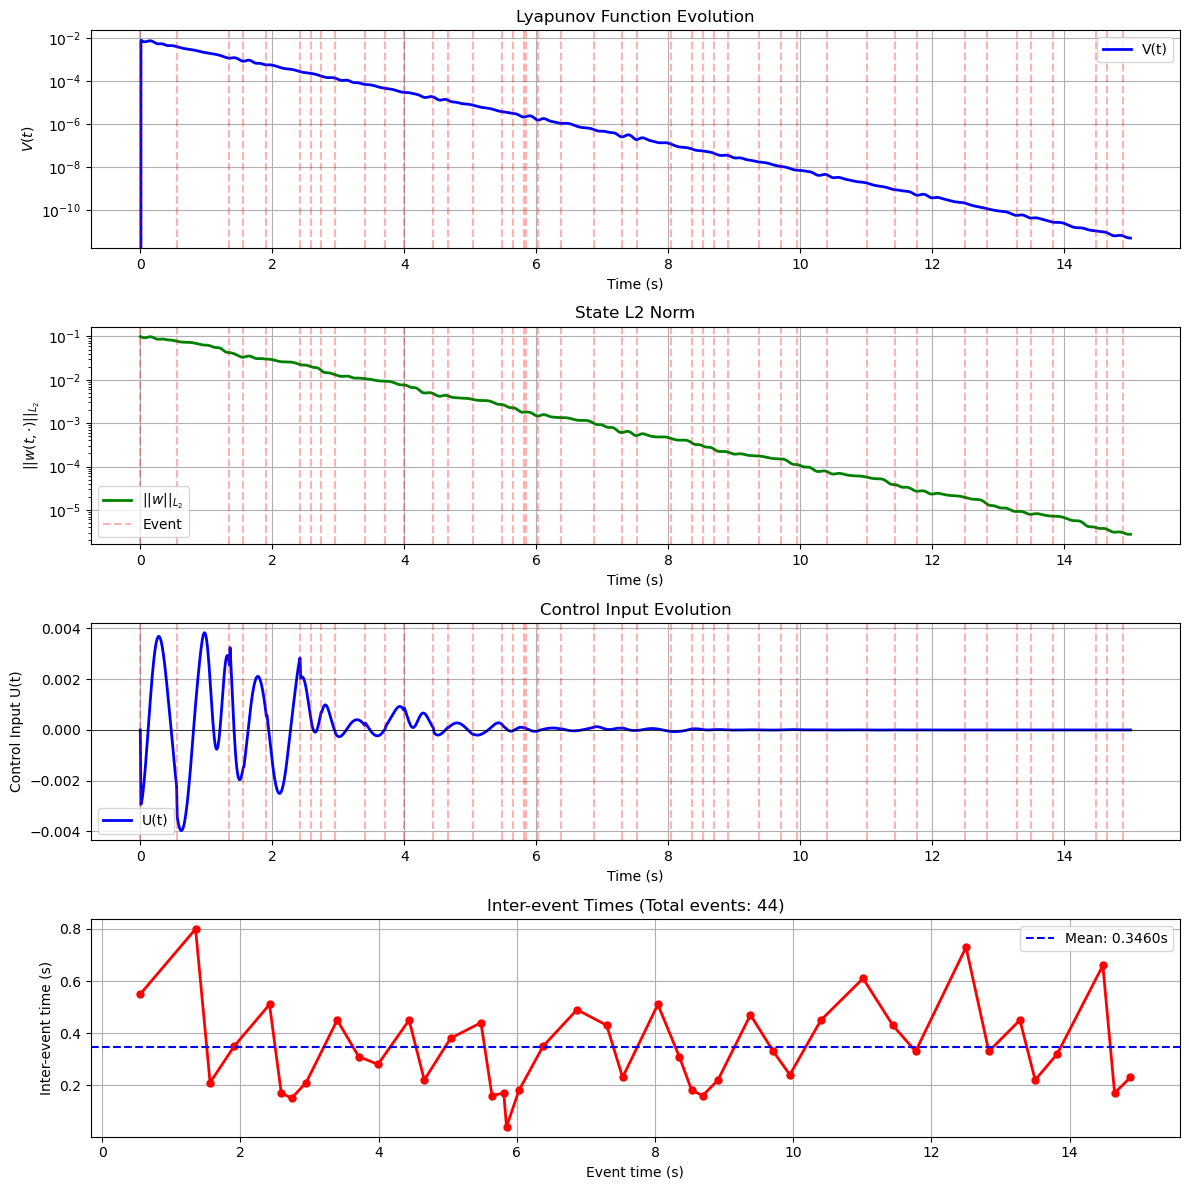


Event statistics:
  Min inter-event: 0.0400s
  Max inter-event: 0.8000s
  Mean inter-event: 0.3460s
  Total events: 44

Control input statistics:
  Max |U|: 0.003966
  Final U: -0.000000


In [10]:
# Extract u and v
u_log = x_log_all[:, :sys.N]
v_log = x_log_all[:, sys.N:2*sys.N]

# Compute state L2 norm
norm_log = np.sqrt(np.sum(u_log**2 + v_log**2, axis=1) * sys.Delta)

# Plots
fig, axes = plt.subplots(4, 1, figsize=(12, 12))

# 1. Lyapunov function
axes[0].semilogy(sys.Tspan, V_log, 'b-', linewidth=2, label='V(t)')
for et in event_times:
    axes[0].axvline(x=et, color='r', linestyle='--', alpha=0.3)
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel(r'$V(t)$')
axes[0].set_title('Lyapunov Function Evolution')
axes[0].grid(True)
axes[0].legend()

# 2. L2 norm
axes[1].semilogy(sys.Tspan, norm_log, 'g-', linewidth=2, label=r'$||w||_{L_2}$')
for et in event_times:
    axes[1].axvline(x=et, color='r', linestyle='--', alpha=0.3, label='Event' if et == event_times[0] else '')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel(r'$||w(t,·)||_{L_2}$')
axes[1].set_title('State L2 Norm')
axes[1].grid(True)
axes[1].legend()

# 3. Control input
axes[2].plot(sys.Tspan, U_log, 'b-', linewidth=2, label='U(t)')
axes[2].axhline(y=0, color='k', linestyle='-', linewidth=0.5)
for et in event_times:
    axes[2].axvline(x=et, color='r', linestyle='--', alpha=0.3)
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Control Input U(t)')
axes[2].set_title('Control Input Evolution')
axes[2].grid(True)
axes[2].legend()

# 4. Event timing
event_intervals = np.diff(event_times)
axes[3].plot(event_times[1:], event_intervals, 'ro-', linewidth=2, markersize=5)
axes[3].set_xlabel('Event time (s)')
axes[3].set_ylabel('Inter-event time (s)')
axes[3].set_title(f'Inter-event Times (Total events: {num_events})')
axes[3].grid(True)
axes[3].axhline(y=np.mean(event_intervals), color='b', linestyle='--', 
                label=f'Mean: {np.mean(event_intervals):.4f}s')
axes[3].legend()

plt.tight_layout()
plt.show()

print("\nEvent statistics:")
print(f"  Min inter-event: {np.min(event_intervals):.4f}s")
print(f"  Max inter-event: {np.max(event_intervals):.4f}s")
print(f"  Mean inter-event: {np.mean(event_intervals):.4f}s")
print(f"  Total events: {num_events}")
print("\nControl input statistics:")
print(f"  Max |U|: {np.max(np.abs(U_log)):.6f}")
print(f"  Final U: {U_log[-1]:.6f}")

## 3D Visualization of u(t,x) and v(t,x)

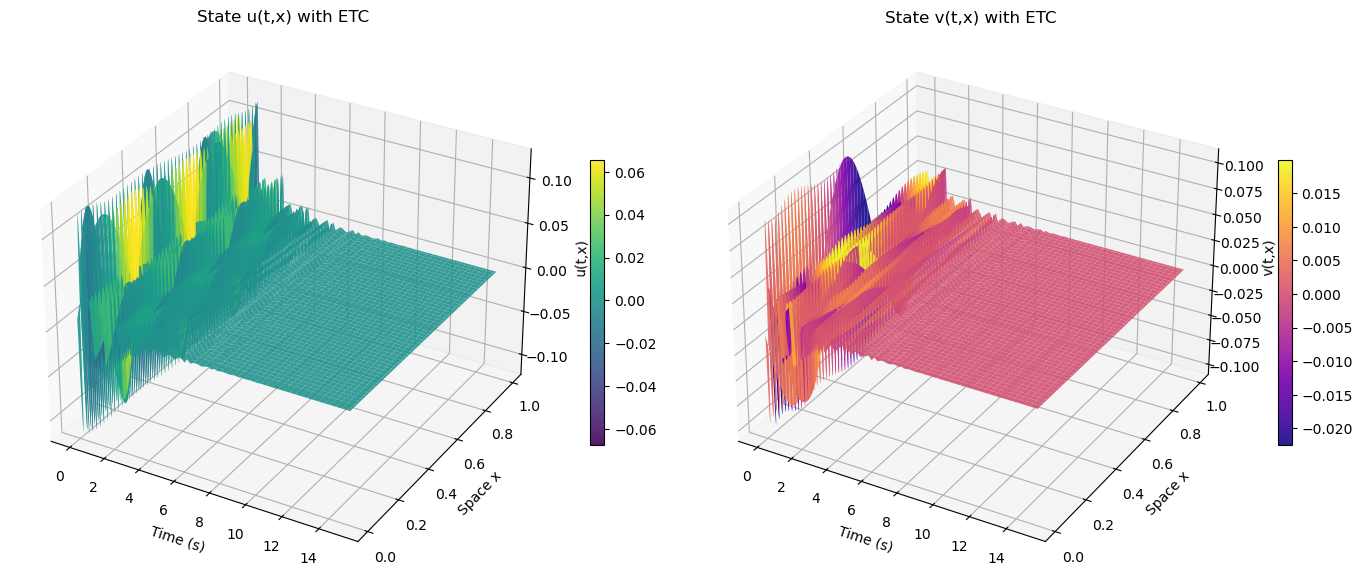

In [11]:
# Create grids
T_mesh, X_mesh = np.meshgrid(sys.Tspan, sys.xspanT)

fig = plt.figure(figsize=(14, 6))

# u(t,x)
ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(T_mesh, X_mesh, u_log.T, cmap='viridis', 
                          edgecolor='none', alpha=0.9)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Space x')
ax1.set_zlabel('u(t,x)')
ax1.set_title('State u(t,x) with ETC')
fig.colorbar(surf1, ax=ax1, shrink=0.5)

# v(t,x)
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(T_mesh, X_mesh, v_log.T, cmap='plasma', 
                          edgecolor='none', alpha=0.9)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Space x')
ax2.set_zlabel('v(t,x)')
ax2.set_title('State v(t,x) with ETC')
fig.colorbar(surf2, ax=ax2, shrink=0.5)

plt.tight_layout()
plt.show()

## Visualize σ⁺(t,x) and σ⁻(t,x) Evolution under ETC

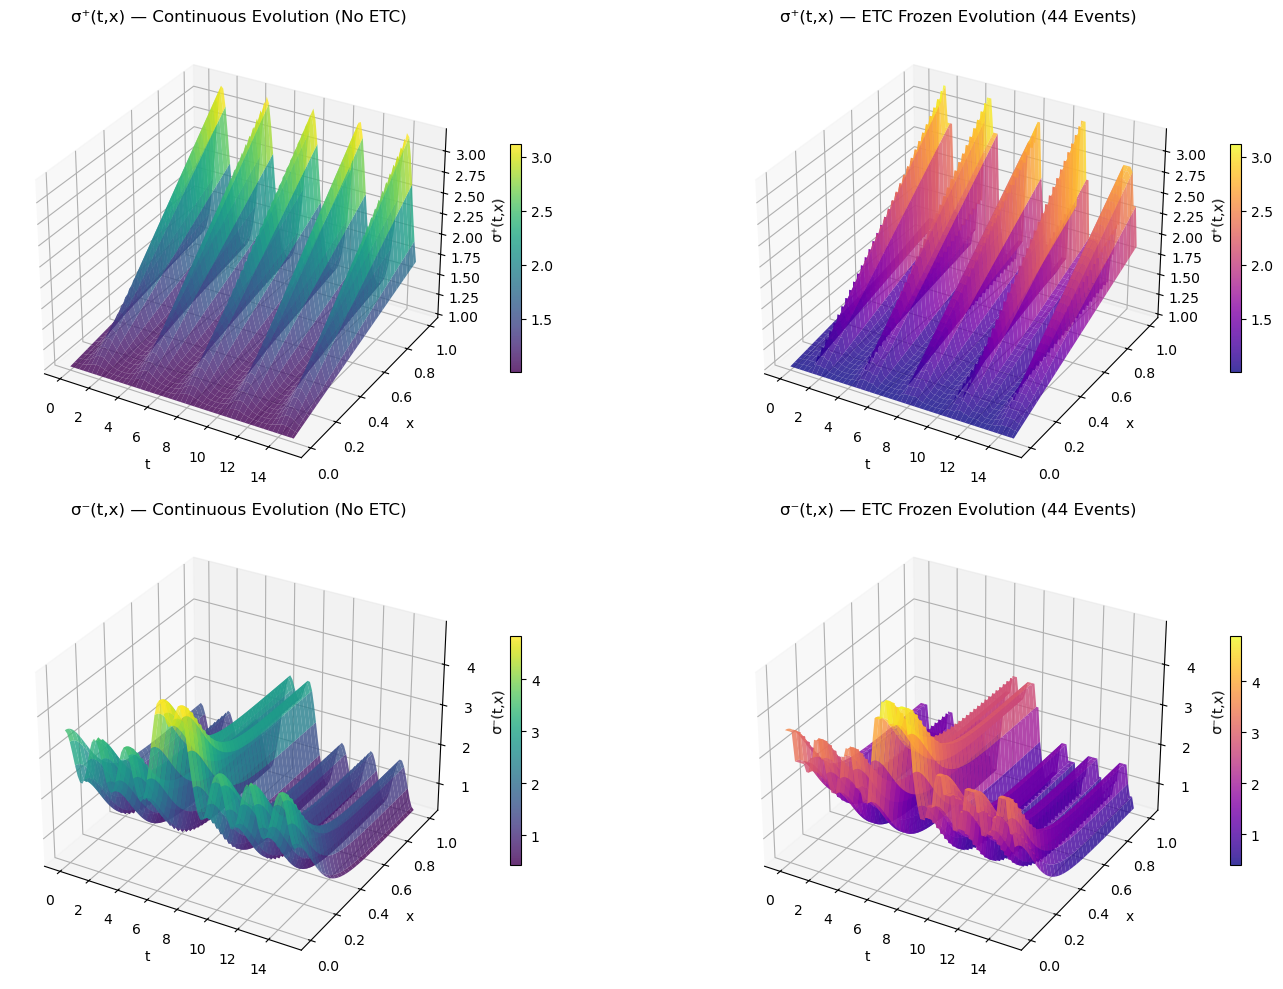


Event times: [0.0, 0.55, 1.35, 1.56, 1.9100000000000001, 2.42, 2.59, 2.74, 2.95, 3.4, 3.71, 3.99, 4.44, 4.66, 5.04, 5.48, 5.64, 5.8100000000000005, 5.8500000000000005, 6.03, 6.38, 6.87, 7.3, 7.53, 8.040000000000001, 8.35, 8.53, 8.69, 8.91, 9.38, 9.71, 9.950000000000001, 10.4, 11.01, 11.44, 11.77, 12.5, 12.83, 13.280000000000001, 13.5, 13.82, 14.48, 14.65, 14.88]
Total number of events: 44
Mean inter-event time: 0.3460 s


In [12]:
# Plot σ⁺(t,x) and σ⁻(t,x) evolution under ETC
# In ETC, these parameters are frozen between event times

# Time and space grids
t_plot = np.linspace(0, sys.T, 100)
x_plot = sys.xspan

T_mesh_sigma, X_mesh_sigma = np.meshgrid(t_plot, x_plot)

# Continuous evolution (true values)
Sigma_plus_true = sigma_plus(T_mesh_sigma, X_mesh_sigma)
Sigma_minus_true = sigma_minus(T_mesh_sigma, X_mesh_sigma)

# ETC evolution (frozen at last event time)
Sigma_plus_etc = np.zeros_like(T_mesh_sigma)
Sigma_minus_etc = np.zeros_like(T_mesh_sigma)

# For each time, find last event time ≤ t and use frozen values
for i, t in enumerate(t_plot):
    event_idx = np.searchsorted(event_times, t, side='right') - 1
    if event_idx < 0:
        event_idx = 0
    t_event = event_times[event_idx]
    
    Sigma_plus_etc[:, i] = sigma_plus(t_event, x_plot)
    Sigma_minus_etc[:, i] = sigma_minus(t_event, x_plot)

# Figures
fig = plt.figure(figsize=(16, 10))

# Subplot 1: σ⁺(t,x) continuous evolution
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
surf1 = ax1.plot_surface(T_mesh_sigma, X_mesh_sigma, Sigma_plus_true, 
                         cmap='viridis', alpha=0.8)
ax1.set_xlabel('t')
ax1.set_ylabel('x')
ax1.set_zlabel('σ⁺(t,x)')
ax1.set_title('σ⁺(t,x) — Continuous Evolution (No ETC)')
plt.colorbar(surf1, ax=ax1, shrink=0.5)

# Subplot 2: σ⁺(t,x) ETC evolution
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
surf2 = ax2.plot_surface(T_mesh_sigma, X_mesh_sigma, Sigma_plus_etc, 
                         cmap='plasma', alpha=0.8)
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_zlabel('σ⁺(t,x)')
ax2.set_title(f'σ⁺(t,x) — ETC Frozen Evolution ({len(event_times)} Events)')
plt.colorbar(surf2, ax=ax2, shrink=0.5)

# Subplot 3: σ⁻(t,x) continuous evolution
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
surf3 = ax3.plot_surface(T_mesh_sigma, X_mesh_sigma, Sigma_minus_true, 
                         cmap='viridis', alpha=0.8)
ax3.set_xlabel('t')
ax3.set_ylabel('x')
ax3.set_zlabel('σ⁻(t,x)')
ax3.set_title('σ⁻(t,x) — Continuous Evolution (No ETC)')
plt.colorbar(surf3, ax=ax3, shrink=0.5)

# Subplot 4: σ⁻(t,x) ETC evolution
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
surf4 = ax4.plot_surface(T_mesh_sigma, X_mesh_sigma, Sigma_minus_etc, 
                         cmap='plasma', alpha=0.8)
ax4.set_xlabel('t')
ax4.set_ylabel('x')
ax4.set_zlabel('σ⁻(t,x)')
ax4.set_title(f'σ⁻(t,x) — ETC Frozen Evolution ({len(event_times)} Events)')
plt.colorbar(surf4, ax=ax4, shrink=0.5)

plt.tight_layout()
plt.show()

print(f"\nEvent times: {event_times}")
print(f"Total number of events: {len(event_times)}")
if len(event_times) > 1:
    print(f"Mean inter-event time: {np.mean(np.diff(event_times)):.4f} s")
else:
    print("Mean inter-event time: N/A (only one event)")

## Event-Triggering Condition Visualization

Plot the triggering condition: $2\langle g w, e_j \rangle > \nu R_L V(t)$, with event times marked.

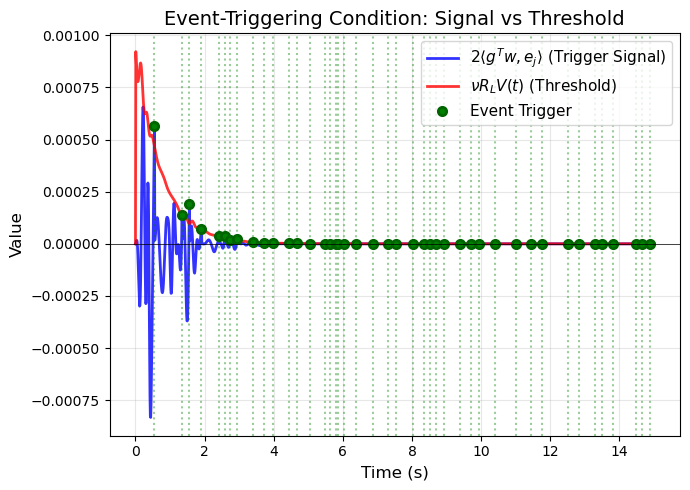


Event-Triggering Statistics:
  Total time steps where condition satisfied: 43/1501 (2.86%)
  Actual events triggered: 43
  Event times: ['0.0000', '0.5500', '1.3500', '1.5600', '1.9100', '2.4200', '2.5900', '2.7400', '2.9500', '3.4000', '3.7100', '3.9900', '4.4400', '4.6600', '5.0400', '5.4800', '5.6400', '5.8100', '5.8500', '6.0300', '6.3800', '6.8700', '7.3000', '7.5300', '8.0400', '8.3500', '8.5300', '8.6900', '8.9100', '9.3800', '9.7100', '9.9500', '10.4000', '11.0100', '11.4400', '11.7700', '12.5000', '12.8300', '13.2800', '13.5000', '13.8200', '14.4800', '14.6500', '14.8800']

Triggering condition: 2⟨g^T w, e_j⟩ > ν R_L V(t)
  where ν=1.2, R_L=0.1


In [13]:
# Plot event-triggering condition: 2⟨g w, e_j⟩ vs ν R_L V(t)
# The triggering condition is satisfied when the left side exceeds the right side

# Compute the triggering signal (left side) and threshold (right side) for all time steps
from networkx import difference


trigger_signal = error_log  # already computed as 2⟨g w, e_j⟩
threshold = nu_param * R_L * V_log  # ν R_L V(t)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(sys.Tspan, trigger_signal, 'b-', linewidth=2, label=r'$2\langle g^T w, e_j \rangle$ (Trigger Signal)', alpha=0.8)
ax.plot(sys.Tspan, threshold, 'r-', linewidth=2, label=r'$\nu R_L V(t)$ (Threshold)', alpha=0.8)

# Mark event times (crossover points where signal > threshold)
for et in event_times[1:]:  # skip t=0
    idx = np.argmin(np.abs(sys.Tspan - et))
    ax.plot(et, trigger_signal[idx], 'go', markersize=6, 
            markeredgecolor='darkgreen', markeredgewidth=2, 
            label='Event Trigger' if et == event_times[1] else '')
    ax.axvline(et, color='green', linestyle=':', alpha=0.4, linewidth=1.5)

ax.axhline(0, color='k', linestyle='-', linewidth=0.5)
ax.set_xlabel('Time (s)', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.set_title('Event-Triggering Condition: Signal vs Threshold', fontsize=14)
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

difference = error_log - threshold

# Statistics
trigger_count = np.sum(difference > 0)
trigger_percentage = 100 * trigger_count / len(sys.Tspan)
print(f"\nEvent-Triggering Statistics:")
print(f"  Total time steps where condition satisfied: {trigger_count}/{len(sys.Tspan)} ({trigger_percentage:.2f}%)")
print(f"  Actual events triggered: {num_events - 1}")  # minus initial event at t=0
print(f"  Event times: {[f'{et:.4f}' for et in event_times]}")
print(f"\nTriggering condition: 2⟨g^T w, e_j⟩ > ν R_L V(t)")
print(f"  where ν={nu_param}, R_L={R_L}")

In [14]:
# Save simulation results to a single archive for reuse
save_path = "etc_lyapunov_simulation_results.npz"
# Ensure threshold is precomputed and error_log included for post-processing
threshold = nu_param * R_L * V_log
np.savez(
    save_path,
    Tspan=sys.Tspan,
    xspanT=sys.xspanT,
    u_log=u_log,
    v_log=v_log,
    V_log=V_log,
    U_log=U_log,
    event_times=np.array(event_times),
    event_intervals=event_intervals,
    R_L=R_L,
    nu_param=nu_param,
    zeta=zeta,
    error_log=error_log,
    threshold=threshold,
)
print(f"Saved results to {save_path}")
print(f"Archive keys: {np.load(save_path).files}")


Saved results to etc_lyapunov_simulation_results.npz
Archive keys: ['Tspan', 'xspanT', 'u_log', 'v_log', 'V_log', 'U_log', 'event_times', 'event_intervals', 'R_L', 'nu_param', 'zeta', 'error_log', 'threshold']
